In [241]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("Customer Churn.csv")

In [242]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [243]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [244]:
df.isnull().sum().sum()

np.int64(0)

In [245]:
df.duplicated().sum()

np.int64(0)

In [246]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


# Data Cleaning.

In [248]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors='coerce')

In [247]:
def conve(value):
    if value == 1:
        return "yes"
    else:
        return"no"

df["SeniorCitizen"]=df["SeniorCitizen"].apply(conve)

In [249]:
df=df.fillna(0)

# Data Visualization.

# 1] The total count of churn

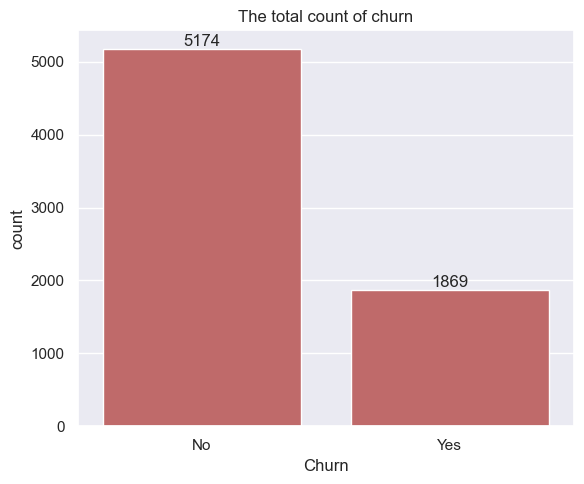

In [250]:
plt.figure(figsize=(6, 5))
sns.set(style="darkgrid")
ax=sns.countplot(data=df,x="Churn",color="indianred")
ax.bar_label(ax.containers[0])
plt.title("The total count of churn")
plt.tight_layout()

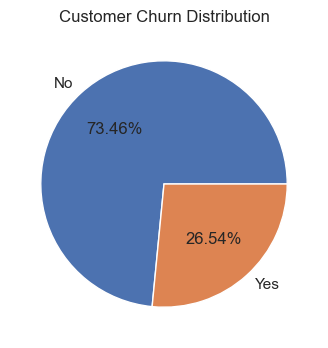

In [251]:
plt.figure(figsize=(4, 4))
sns.set(style="darkgrid")
gb = df["Churn"].value_counts()
plt.pie(gb.values,labels=gb.index,autopct="%1.2f%%")
plt.title("Customer Churn Distribution")
plt.show()

**There are total 26.54% of the customers who churned.**

# 2] Customer Churn Count by Gender.

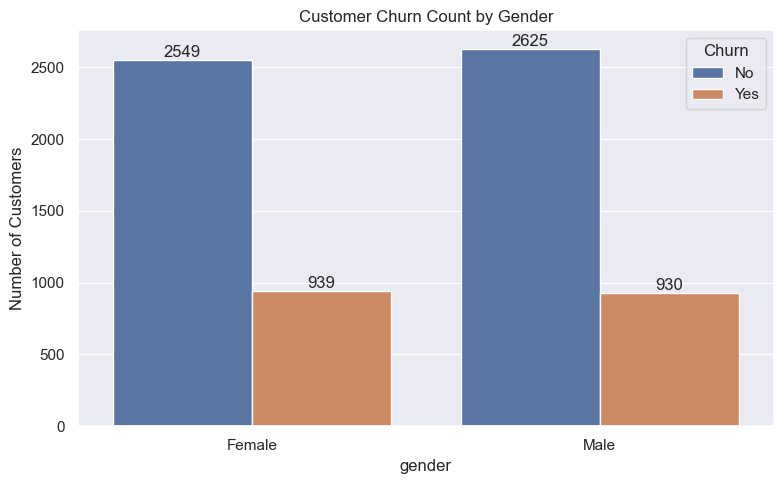

In [252]:
plt.figure(figsize=(8, 5))
sns.set(style="darkgrid")
ax=sns.countplot(data=df,x="gender",hue="Churn",palette="deep")
for container in ax.containers:
    ax.bar_label(container)
plt.title("The total count of churn")
plt.title("Customer Churn Count by Gender")
plt.xlabel("gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**The Churn of the Customers is not based on the gender.**

# 3]Customer Churn Count by SeniorCitizen

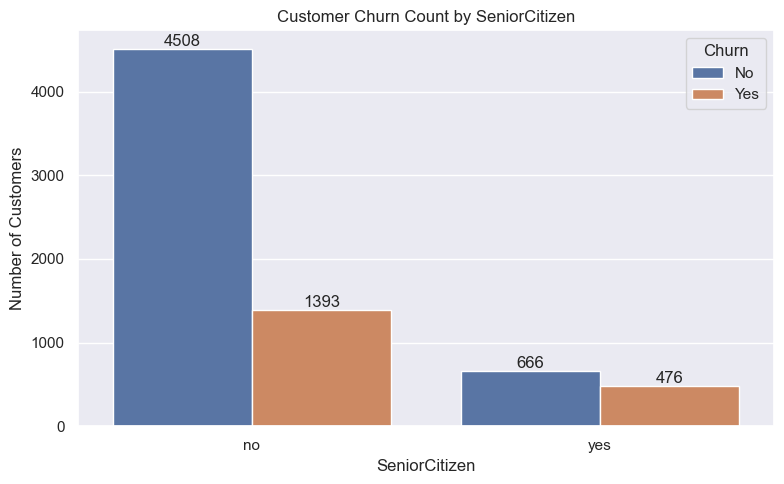

In [254]:
plt.figure(figsize=(8, 5))
sns.set(style="darkgrid")
ax=sns.countplot(data=df,x="SeniorCitizen",hue="Churn",palette="deep")
for container in ax.containers:
    ax.bar_label(container)
plt.title("The total count of churn")
plt.title("Customer Churn Count by SeniorCitizen")
plt.xlabel("SeniorCitizen")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**Comparitively, the senior citizen are churned mmost.**

# 4]Customer Churn Count by The Contract.

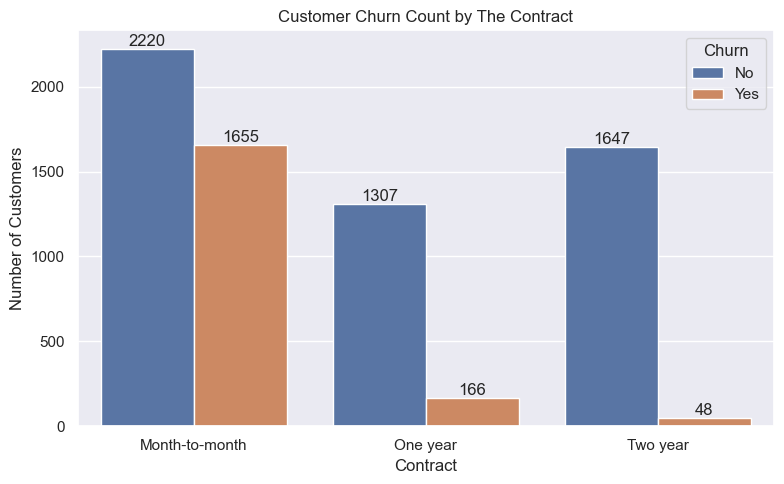

In [205]:
plt.figure(figsize=(8, 5))
sns.set(style="darkgrid")
ax=sns.countplot(data=df,x="Contract",hue="Churn",palette="deep")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Customer Churn Count by The Contract")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


**people who have month to month contract are likely to churn then from those who have 1 or 2 years or contract.**

# 5] Customer Churn Count by The Contract.

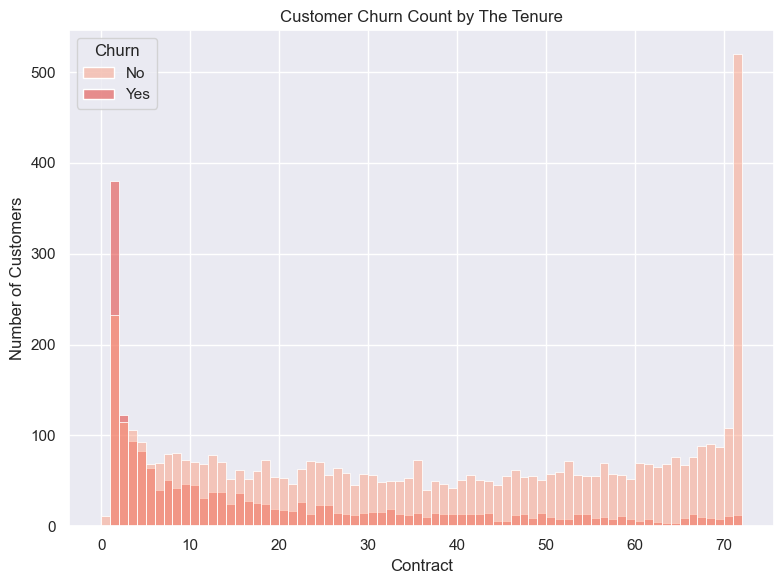

In [263]:
plt.figure(figsize=(8, 6))
sns.set(style="darkgrid")
sns.histplot(x="tenure",data=df,hue="Churn",bins=72,palette="Reds")
plt.title("Customer Churn Count by The Tenure")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**The customer who had used ther service for 1 month are churned, the customer who used the service for the more time are not.**

In [ ]:
# 6]

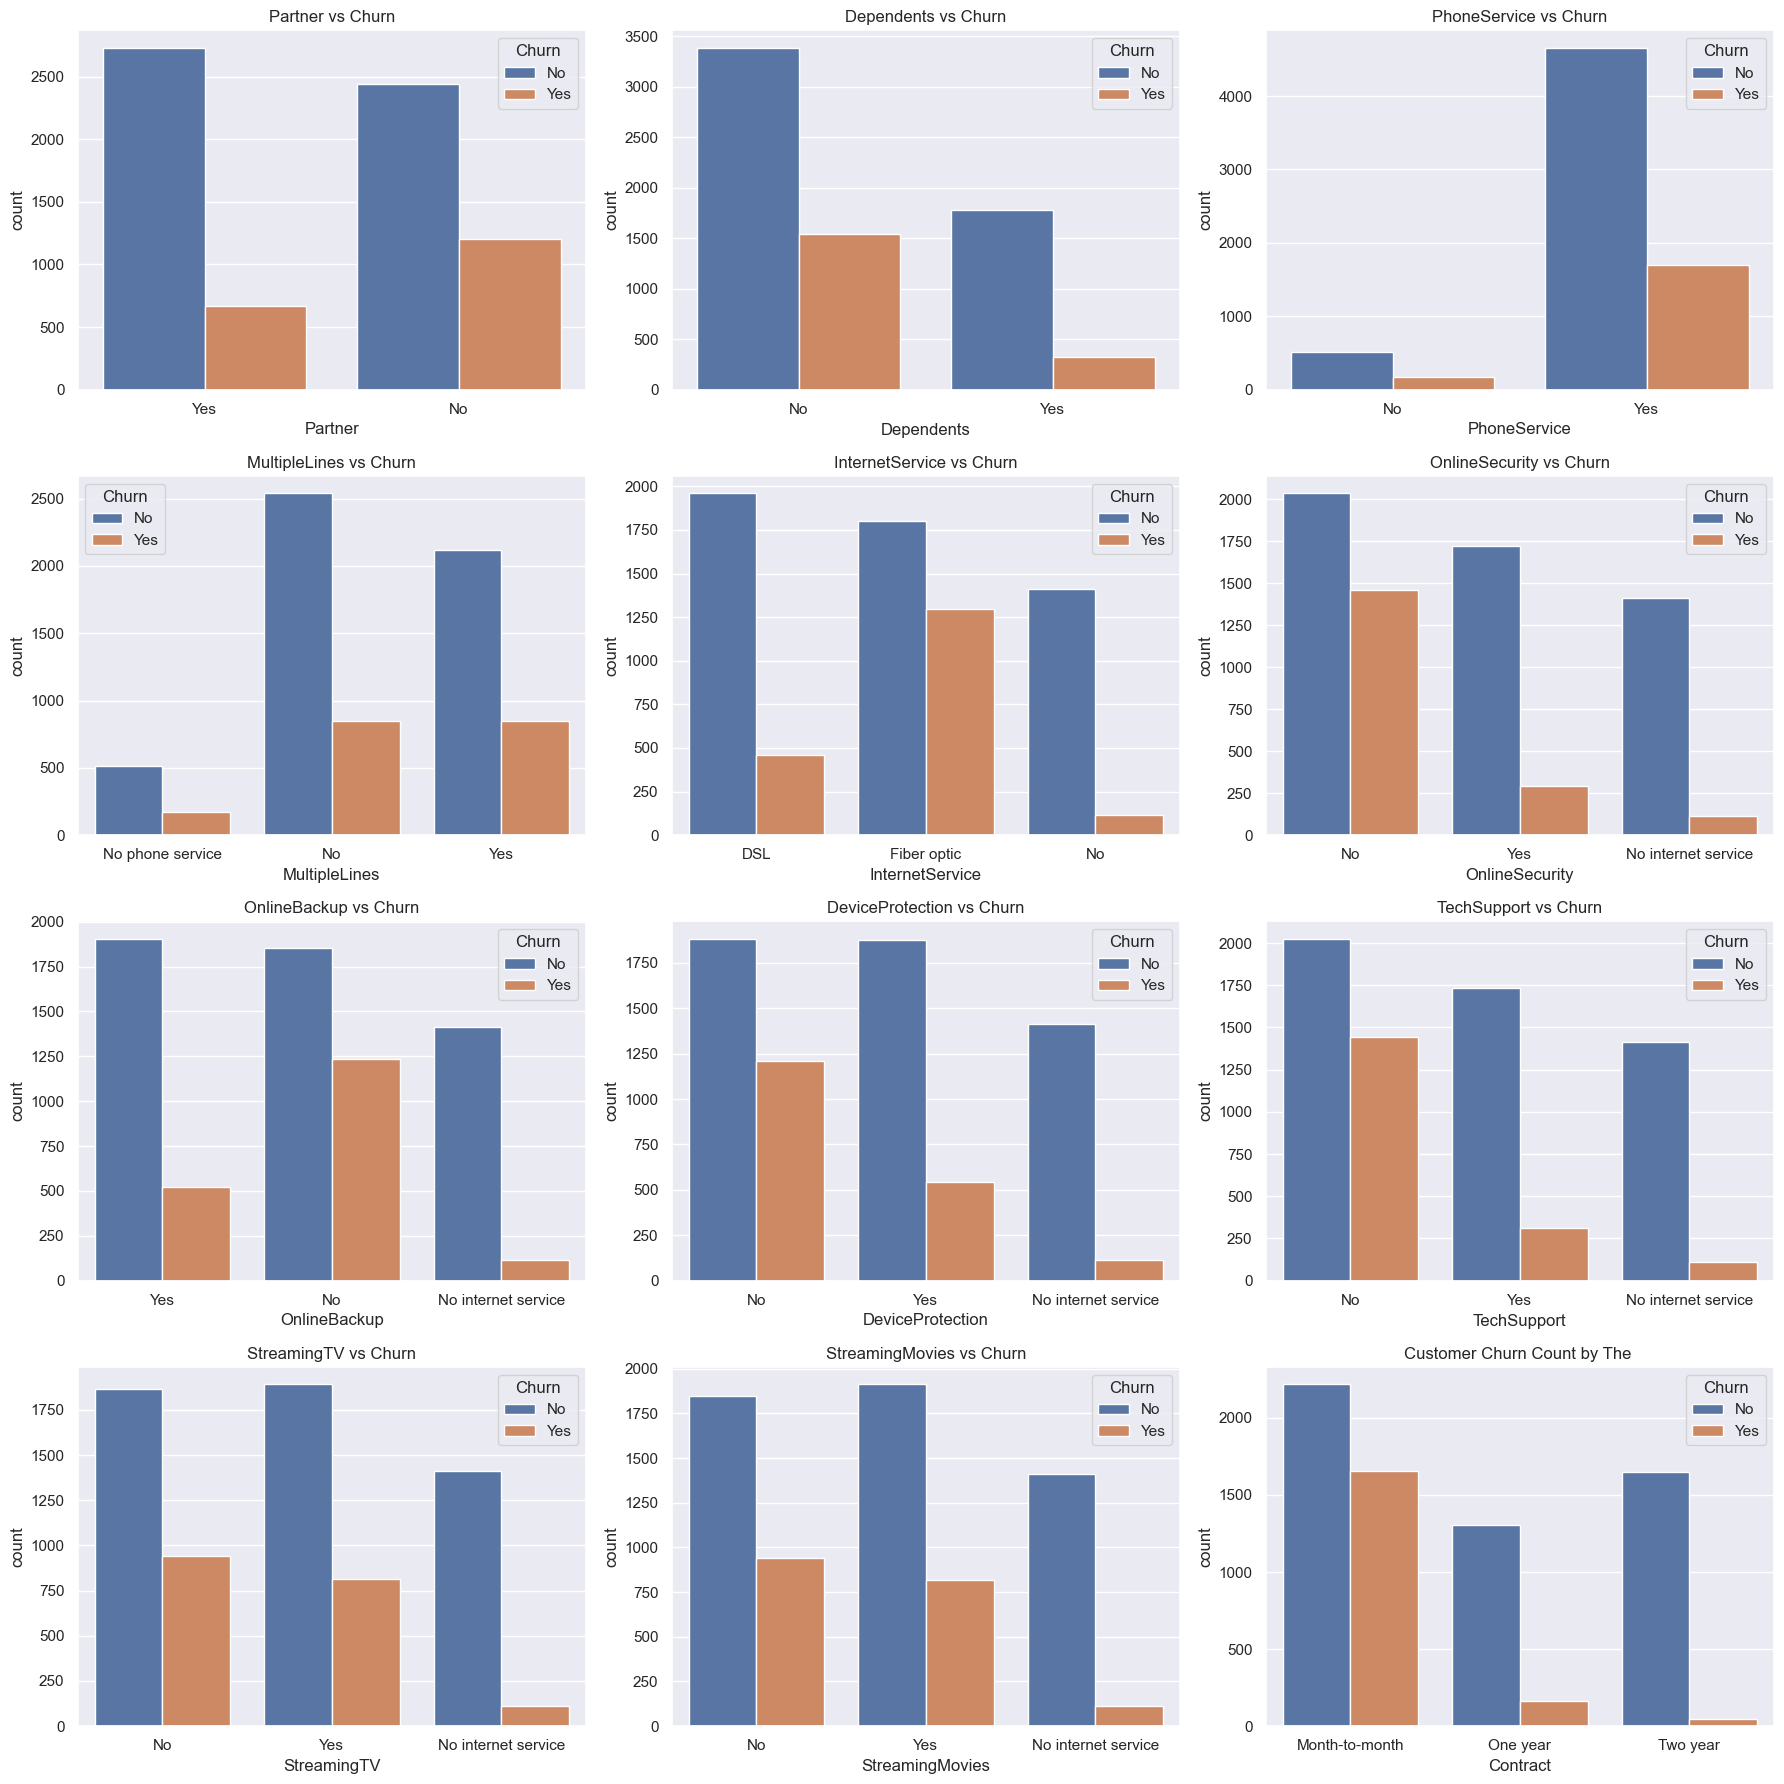

In [273]:
columns = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity','OnlineBackup', 'DeviceProtection', 'TechSupport','StreamingTV', 'StreamingMovies',"Contract"]
palette = "deep"
fig, ax = plt.subplots(4, 3, figsize=(18, 18))
ax = ax.flatten()
for i, col in enumerate(columns):
    sns.countplot(data=df,x=col,hue='Churn',ax=ax[i],palette=palette
    )

    ax[i].set_title(f'{col} vs Churn')
    ax[i].tick_params(axis='x')
plt.tight_layout()
plt.title("Customer Churn Count by The ")
plt.show()



1. **Partner:** Customers without a partner have a higher churn count than customers with a partner.

2. **Dependents:** Customers without dependents have a higher churn count than customers with dependents.

3. **Phone Service:** Customers with phone service have a higher churn count than customers without phone service.

4. **Multiple Lines:** Customers with and without multiple lines both show substantial churn counts.

5. **Internet Service:** Fiber optic customers have a higher churn count than DSL and no-internet-service customers.

6. **Online Security:** Customers without online security have a higher churn count than customers with online security.

7. **Online Backup:** Customers without online backup have a higher churn count than customers with online backup.

8. **Device Protection:** Customers without device protection have a higher churn count than customers with device protection.

9. **Tech Support:** Customers without tech support have a higher churn count than customers with tech support.

10. **Streaming TV:** Customers with and without StreamingTV both show substantial churn counts.

11. **Streaming Movies:** Customers with and without StreamingMovies both show substantial churn counts.

12. **Contract:** The Contract plot was not visible in the chart, so no insight can be drawn from it.


In [266]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,no,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,no,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,no,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,no,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,no,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,no,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,no,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,no,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,yes,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes
